In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path

print("Demand forecasting enviornment initialization")




Demand forecasting enviornment initialization


In [4]:

BASE_DIR = Path.cwd().parent

PROCESSED_DIR= BASE_DIR/ "data" / "processed"

train = pd.read_csv(
    PROCESSED_DIR/ "train_daily_demand.csv"
)


validation = pd.read_csv(
    PROCESSED_DIR / "validation_daily_demand.csv"
)

train["date"]= pd.to_datetime(train["date"])
validation["date"]= pd.to_datetime(validation["date"])

print("Training Shape:", train.shape)
print("Validation shape", validation.shape)

print("\nTraining Period:")


print(train["date"].min(), "to", train["date"].max())

print("\nValidation period:")
print(validation["date"].min(), "to", validation["date"].max())

Training Shape: (1913, 2)
Validation shape (28, 2)

Training Period:
2011-01-29 00:00:00 to 2016-04-24 00:00:00

Validation period:
2016-04-25 00:00:00 to 2016-05-22 00:00:00


In [5]:
prophet_train = train[[
    "date",
    "units_sold"
]].copy()

prophet_train.columns=[
    "ds",
    "y"
]
print(prophet_train.head())
print(prophet_train.shape)

          ds      y
0 2011-01-29  32631
1 2011-01-30  31749
2 2011-01-31  23783
3 2011-02-01  25412
4 2011-02-02  19146
(1913, 2)


In [6]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "prophet"
])



0

In [7]:
from prophet import Prophet
print("Prophet imported successfully!")


Prophet imported successfully!


In [8]:
from prophet import Prophet
print("Promphet imported successfully.")


Promphet imported successfully.


In [ ]:
from prophet import Prophet


model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(prophet_train)

20:12:19 - cmdstanpy - INFO - Chain [1] start processing
20:12:20 - cmdstanpy - INFO - Chain [1] done processing


In [10]:
future = model.make_future_dataframe(
    periods= len(validation),
    freq="D"
)

forecast = model.predict(future)

print("Forecast generated successfully.")
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(28))

Forecast generated successfully.
             ds          yhat    yhat_lower    yhat_upper
1913 2016-04-25  39462.328911  35343.129154  43965.397349
1914 2016-04-26  36927.511443  32725.978388  41274.907464
1915 2016-04-27  36520.362516  32206.316537  40686.542717
1916 2016-04-28  36669.208759  32408.939981  41204.343992
1917 2016-04-29  40646.223773  36458.378079  45458.404497
1918 2016-04-30  47966.222834  43225.657323  52393.999537
1919 2016-05-01  47509.582629  43276.858425  51998.045671
1920 2016-05-02  39219.258421  34798.928096  43604.813187
1921 2016-05-03  36699.995557  31760.814451  40892.678267
1922 2016-05-04  36308.886057  31924.655936  40721.596954
1923 2016-05-05  36474.606136  32216.306857  40943.713069
1924 2016-05-06  40469.734611  36174.613286  44697.714150
1925 2016-05-07  47809.527669  43295.248644  52286.783592
1926 2016-05-08  47374.816920  43010.074279  51840.480976
1927 2016-05-09  39109.003882  34856.602776  43522.283743
1928 2016-05-10  36617.248645  32388.24

In [11]:
prophet_validation = forecast[
    ["ds", "yhat"]
].tail(28).copy()

prophet_validation.columns=[
    "date",
    "forecast"
]

print(prophet_validation)

           date      forecast
1913 2016-04-25  39462.328911
1914 2016-04-26  36927.511443
1915 2016-04-27  36520.362516
1916 2016-04-28  36669.208759
1917 2016-04-29  40646.223773
1918 2016-04-30  47966.222834
1919 2016-05-01  47509.582629
1920 2016-05-02  39219.258421
1921 2016-05-03  36699.995557
1922 2016-05-04  36308.886057
1923 2016-05-05  36474.606136
1924 2016-05-06  40469.734611
1925 2016-05-07  47809.527669
1926 2016-05-08  47374.816920
1927 2016-05-09  39109.003882
1928 2016-05-10  36617.248645
1929 2016-05-11  36257.004224
1930 2016-05-12  36457.233294
1931 2016-05-13  40490.707969
1932 2016-05-14  47872.768804
1933 2016-05-15  47484.210543
1934 2016-05-16  39268.268215
1935 2016-05-17  36829.801708
1936 2016-05-18  36525.830534
1937 2016-05-19  36784.755543
1938 2016-05-20  40878.668184
1939 2016-05-21  48322.123265
1940 2016-05-22  47995.042340


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = validation["units_sold"].values
predicted = prophet_validation["forecast"].values
prophet_mae = mean_absolute_error(
    actual,
    predicted
)


prophet_rmse= np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

prophet_mape = np.mean(
    np.abs(
        (actual-predicted)/
        np.where(actual == 0, 1, actual)
    )
)*100

print("PROPHET RESULTS")
print("="*40)

print("MAE:", prophet_mae)
print("MAE:", prophet_mape, "%")
print("MAE:", prophet_rmse)


PROPHET RESULTS
MAE: 3806.7687039708485
MAE: 8.222876782133447 %
MAE: 4627.615702501423


In [14]:
baseline_results = pd.read_csv(
    BASE_DIR/"reports"/"model_results" / "baseline_results.csv"
)

forecast_results= pd.concat(
    [
        baseline_results,
        pd.DataFrame({
            "Model":["Prophet"],
            "MAE":[prophet_mae],
            "RMSE":[prophet_rmse],
            "MAPE":[prophet_mape]
        })
    ],
    ignore_index=True
)
forecast_results

,Model,RMSE,MAE,MAPE
0,Naive Forecast,8817.170059,7890.571429,19.395964
1,7-Day Moving Average,7385.367183,5506.387755,11.620051
2,Prophet,4627.615703,3806.768704,8.222877


In [15]:
# from src.load_database import RESULTS_DIR
RESULTS_DIR=BASE_DIR/"reports"/"model_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

forecast_results.to_csv(
    RESULTS_DIR/"forecast_model_results.csv",
    index = False
)

prophet_validation.to_csv(
    RESULTS_DIR /"prophet_validation_forecast.csv",
    index = False
)
print("Forecast results saved successfully.")



Forecast results saved successfully.


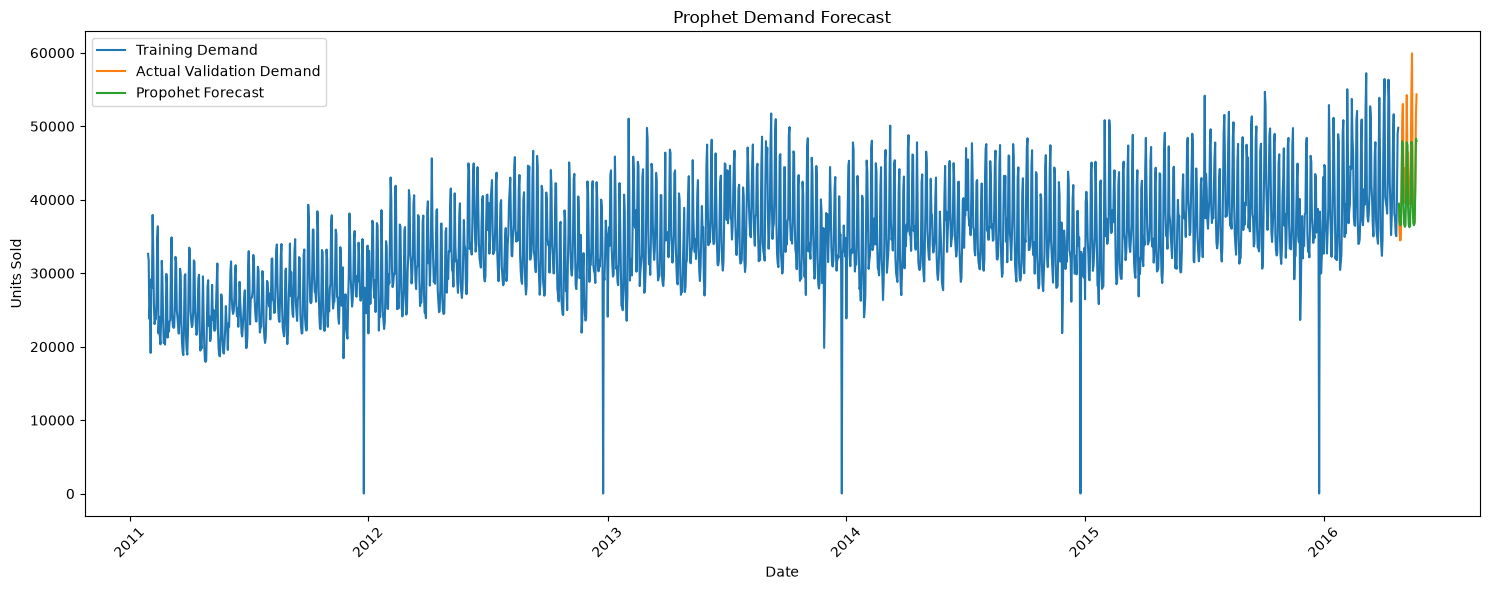

In [16]:
plt.figure(figsize=(15, 6))
plt.plot(
    train["date"],
    train["units_sold"],
    label="Training Demand"
)

plt.plot(
    validation["date"],
    validation["units_sold"],
    label="Actual Validation Demand"
)

plt.plot(
    prophet_validation["date"],
    prophet_validation["forecast"],
    label = "Propohet Forecast"
)

plt.title("Prophet Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "lightgbm"
])



0

In [18]:
from lightgbm import LGBMRegressor

print("LightGBM imported successfully!")


LightGBM imported successfully!


In [19]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from lightgbm import LGBMRegressor

# from sklearn.metrics import mean_absolute_error, mean_squared_error
from pathlib import Path

In [20]:
BASE_DIR = Path.cwd().parent

SALES_PATH = BASE_DIR / "data" / "raw" / "sales_train_evaluation.csv"

sales = pd.read_csv(SALES_PATH)

print("Sales data loaded successfully.")
print("Shape:", sales.shape)

Sales data loaded successfully.
Shape: (30490, 1947)


In [21]:

day_columns=[
    column for column in sales.columns
    if column.startswith("d_")
]

print("Number of daily columns:", len(day_columns))
print("First 5:", day_columns[:5])
print("Last 5:", day_columns[-5:])

Number of daily columns: 1941
First 5: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5']
Last 5: ['d_1937', 'd_1938', 'd_1939', 'd_1940', 'd_1941']


In [22]:

sales["total_units"]= sales[day_columns].sum(axis=1)

top_series = sales.nlargest(
    50,
    "total_units"
).copy()


print("Top item-store series selected:", len(top_series))

print(
    top_series[
        ["item_id", "dept_id", "cat_id", "store_id", "state_id", "total_units"]
    ].head(10)
)



Top item-store series selected: 50
           item_id  dept_id cat_id store_id state_id  total_units
8412   FOODS_3_090  FOODS_3  FOODS     CA_3       CA       253859
18055  FOODS_3_586  FOODS_3  FOODS     TX_2       TX       195120
21104  FOODS_3_586  FOODS_3  FOODS     TX_3       TX       151862
8908   FOODS_3_586  FOODS_3  FOODS     CA_3       CA       136269
2314   FOODS_3_090  FOODS_3  FOODS     CA_1       CA       128855
29755  FOODS_3_090  FOODS_3  FOODS     WI_3       WI       123500
17559  FOODS_3_090  FOODS_3  FOODS     TX_2       TX       121275
20608  FOODS_3_090  FOODS_3  FOODS     TX_3       TX       116773
17721  FOODS_3_252  FOODS_3  FOODS     TX_2       TX       115613
15006  FOODS_3_586  FOODS_3  FOODS     TX_1       TX       114010


/var/folders/_z/bqgq5b9n4xgck8k0mq09_ttw0000gn/T/ipykernel_14463/17207562.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales["total_units"]= sales[day_columns].sum(axis=1)
